# OLS - Ordinay Least Square Method 
- Using the LinearRegression Model directly from the Sklearn


<pre>

Dataset
   ↓
Cleaning / preprocessing
   ↓
Select X and y
   ↓
Train-test split
   ↓
Linear Regression (OLS)
   ↓
Fit on training data
   ↓
Predict test data
   ↓
MAE
MSE
RMSE
Ordinary R²
Adjusted R²
   ↓
Assumption checks
   ├── Linearity
   ├── Independence
   ├── Homoscedasticity
   ├── Normality
   └── Multicollinearity
       (only relevant when multiple features exist)

</pre>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score


In [2]:
house_data = pd.read_csv("data/kc_house_data.csv")

In [3]:
house_data.head()

,sqft_living,price
0,1180,221900.0
1,2570,538000.0
2,770,180000.0
3,1960,604000.0
4,1680,510000.0


In [4]:
# X = house_data.iloc[:,0]
X = house_data[["sqft_living"]]
X

,sqft_living
0,1180
1,2570
2,770
3,1960
4,1680
...,...
21608,1530
21609,2310
21610,1020
21611,1600


In [5]:
# y = house_data.iloc[:,1]
y = house_data["price"]
y

0        221900.0
1        538000.0
2        180000.0
3        604000.0
4        510000.0
           ...   
21608    360000.0
21609    400000.0
21610    402101.0
21611    400000.0
21612    325000.0
Name: price, Length: 21613, dtype: float64

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
model = LinearRegression()

In [8]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[279.55]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['sqft_living']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.2e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [9]:
model.intercept_

np.float64(-41999.1860399358)

In [10]:
model.coef_[0]

np.float64(279.5547793152631)

In [11]:
y_pred = model.predict(X_test)

In [12]:
y_pred[:10]

array([ 536679.20714266,  768709.67397433, 1011922.33197861,
       1232770.60763766,  670865.50121399,  436039.48658916,
        710003.17031812,  461199.41672754,  405288.46086449,
        212395.66313695])

In [13]:
y_test.iloc[:10].values

array([ 365000.,  865000., 1038000., 1490000.,  711000.,  211000.,
        790000.,  680000.,  384500.,  605000.])

### MAE

In [14]:
mae = mean_absolute_error(y_test, y_pred)
mae

177867.54034434847

### MSE

In [15]:
mse = mean_squared_error(y_test, y_pred)
mse

76484977061.77612

### RMSE

In [16]:
rmse = root_mean_squared_error(y_test, y_pred)
rmse

276559.1746114674

### R2_Score

In [17]:
ordinay_r2_score = r2_score(y_test, y_pred)
ordinay_r2_score

0.49406905389089006

### Visualizing

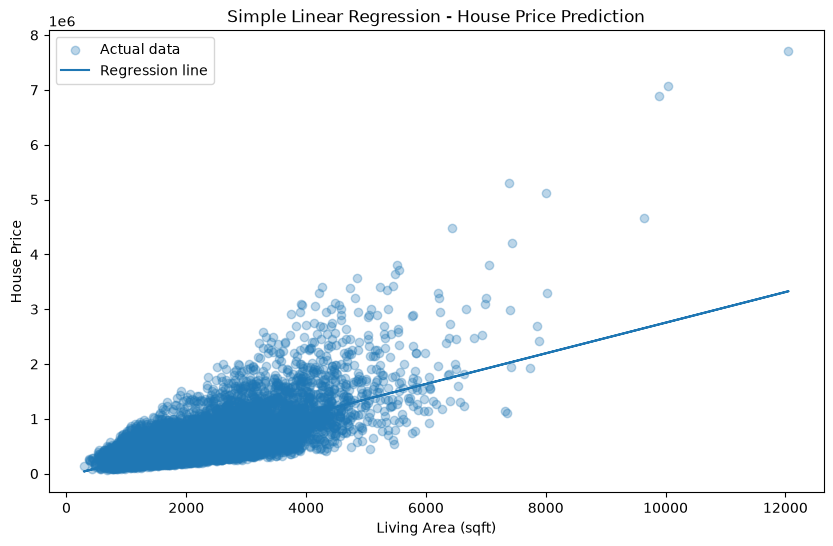

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3, label="Actual data")

plt.plot(X_train, model.predict(X_train), label="Regression line")

plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.title("Simple Linear Regression - House Price Prediction")

plt.legend()
plt.show()

In [19]:
b0 = model.intercept_
b1 = model.coef_[0]

print("Intercept:", b0)
print("Coefficient:", b1)
print(f"Equation: ŷ = {b0:.2f} + {b1:.2f} × sqft_living")

Intercept: -41999.1860399358
Coefficient: 279.5547793152631
Equation: ŷ = -41999.19 + 279.55 × sqft_living


### Adjusted r2_score

In [20]:
n = len(y_test)
p = X_test.shape[1]

adjusted_r2_score = 1 - ((1 - ordinay_r2_score) * (n - 1)) / (n - p - 1)
adjusted_r2_score

0.49395196734932345

### Residual

In [21]:
residuals = y_test - y_pred
residuals

735     -171679.207143
2830      96290.326026
4106      26077.668021
16218    257229.392362
19964     40134.498786
             ...      
13674     30555.711896
20377    -76140.839422
8805    -353437.146813
10168     18000.932581
2522    -319956.596800
Name: price, Length: 4323, dtype: float64

In [22]:
residuals.describe()

count    4.323000e+03
mean     3.206783e+03
std      2.765726e+05
min     -1.463173e+06
25%     -1.444797e+05
50%     -2.387956e+04
75%      1.081893e+05
max      3.155561e+06
Name: price, dtype: float64

## Assumptions

### Homoscedasticity

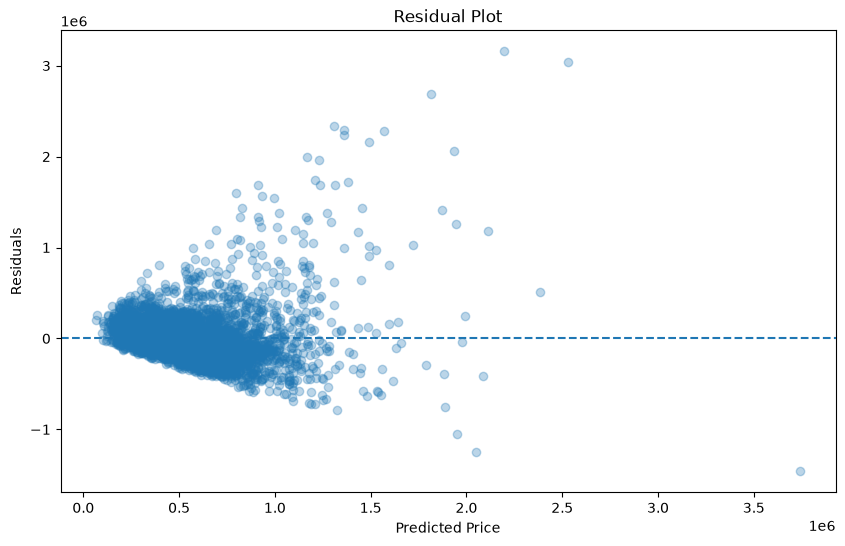

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

>The residual plot shows an increasing spread of residuals as the predicted price increases, suggesting that the homoscedasticity assumption may not be satisfied.

### Normality

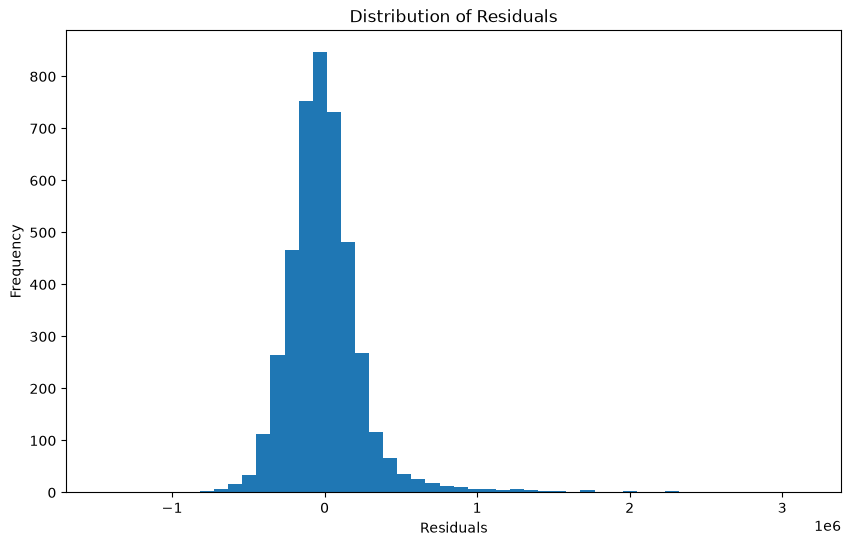

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(residuals, bins=50)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

>The residual distribution is right-skewed with a long positive tail, suggesting that the normality assumption is not well satisfied.

### Linearity

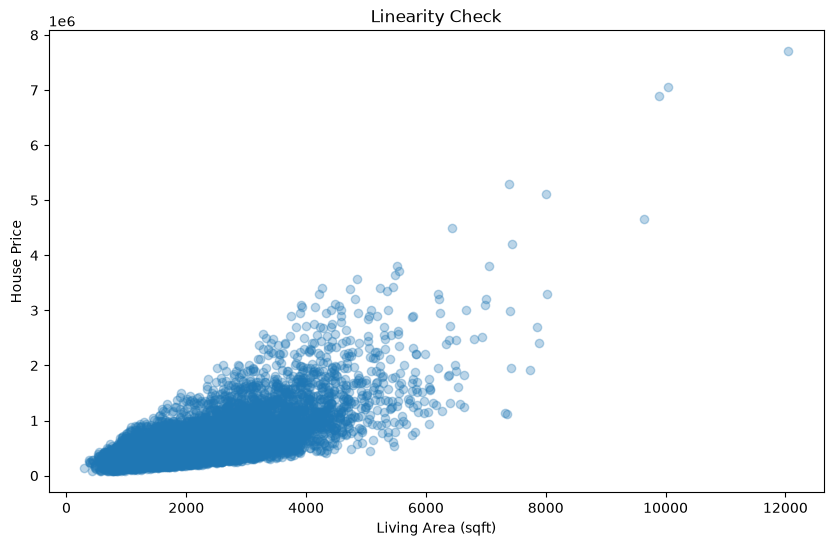

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3)

plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.title("Linearity Check")

plt.show()

> Linearity: The scatter plot shows an overall positive, approximately linear relationship between living area and house price. Therefore, the linearity assumption appears reasonably satisfied, although there is considerable scatter in the data.

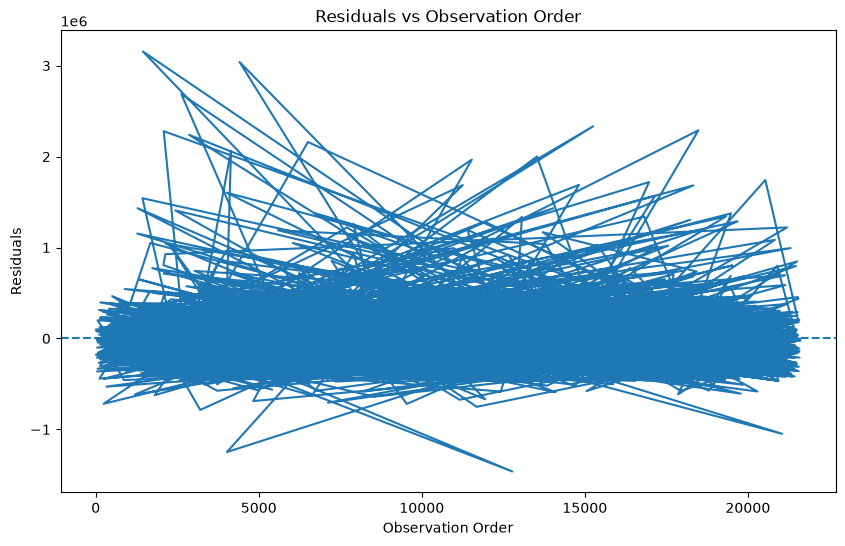

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation Order")
plt.ylabel("Residuals")
plt.title("Residuals vs Observation Order")

plt.show()

### Independence

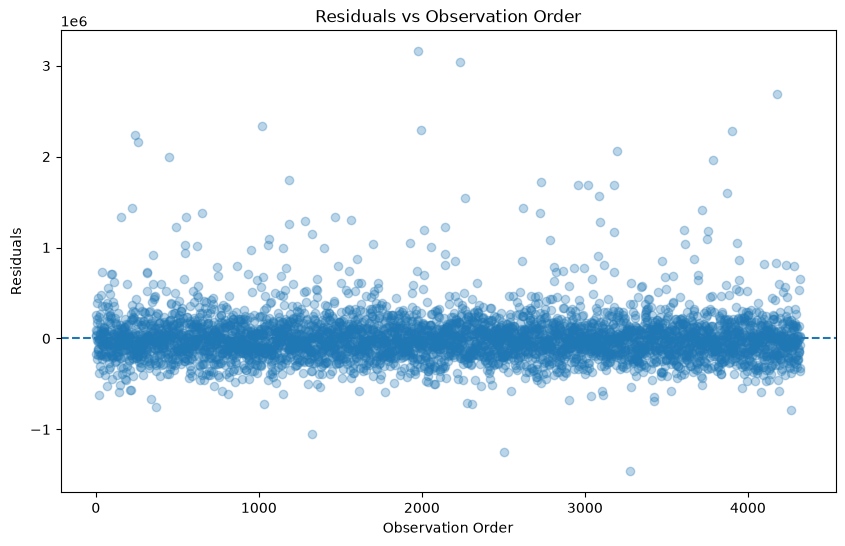

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(range(len(residuals)), residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation Order")
plt.ylabel("Residuals")
plt.title("Residuals vs Observation Order")

plt.show()

> Independence: The residuals show no obvious systematic pattern across observation order. Therefore, there is no clear evidence of dependence from this diagnostic.